# data1a — повреждённые и целые автомобили

Класс определяется папкой: `00-damage` → `damage` (ID 0), `01-whole` → `whole` (ID 1). Уровень разметки — всё изображение; рамок и масок в наборе нет.

`SPLIT`: `training`, `validation`, `all`. Пример фильтра: `CLASS_FILTER = "damage"`.

Запустите ячейки сверху вниз. **Для новой случайной подборки повторите последнюю ячейку.** Настройки: количество фото, выборка, фильтр класса, случайное зерно, контуры, рамки и подписи. Исходные поля выбранной записи: `selected_samples[0]["metadata"]`.


In [1]:
import csv
import json
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "datasets").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Откройте ноутбук из папки проекта с каталогом datasets/.")
VIEWERS_DIR = PROJECT_ROOT / "code" / "viewers"
if str(VIEWERS_DIR) not in sys.path:
    sys.path.insert(0, str(VIEWERS_DIR))

from viewer_common import (
    IMAGE_SUFFIXES, image_files, load_coco, load_supervisely,
    read_jsonl, show_samples, summarize,
)


In [2]:
DATASET_ROOT = PROJECT_ROOT / "datasets" / "data1a"
SPLIT = "training"
N_IMAGES = 6
N_COLS = 3
SEED = None                 # Целое число фиксирует подборку
CLASS_FILTER = None         # Название класса или список; None = все
SHOW_MASKS = True
SHOW_BOXES = True
SHOW_LABELS = True
SHOW_CLASS_IDS = False
ONLY_ANNOTATED = False


In [3]:
def load_dataset(root):
    samples = []
    for split_name in ("training", "validation"):
        for class_folder in sorted((root / split_name).iterdir()):
            if not class_folder.is_dir():
                continue
            prefix, label = class_folder.name.split("-", 1)
            for image in image_files(class_folder):
                samples.append({
                    "image_path": image, "file_name": image.name,
                    "split": split_name, "label": label, "class_id": int(prefix),
                    "annotations": [], "metadata": {
                        "class_folder": class_folder.name,
                        "relative_path": image.relative_to(root).as_posix(),
                    }, "task": "classification",
                })
    return samples

dataset = load_dataset(DATASET_ROOT)
summary = summarize(dataset)


Записей: 2,300; изображения отсутствуют: 0
Выборки: {'training': 1840, 'validation': 460}
Классы (число меток):
  damage: 1,150
  whole: 1,150


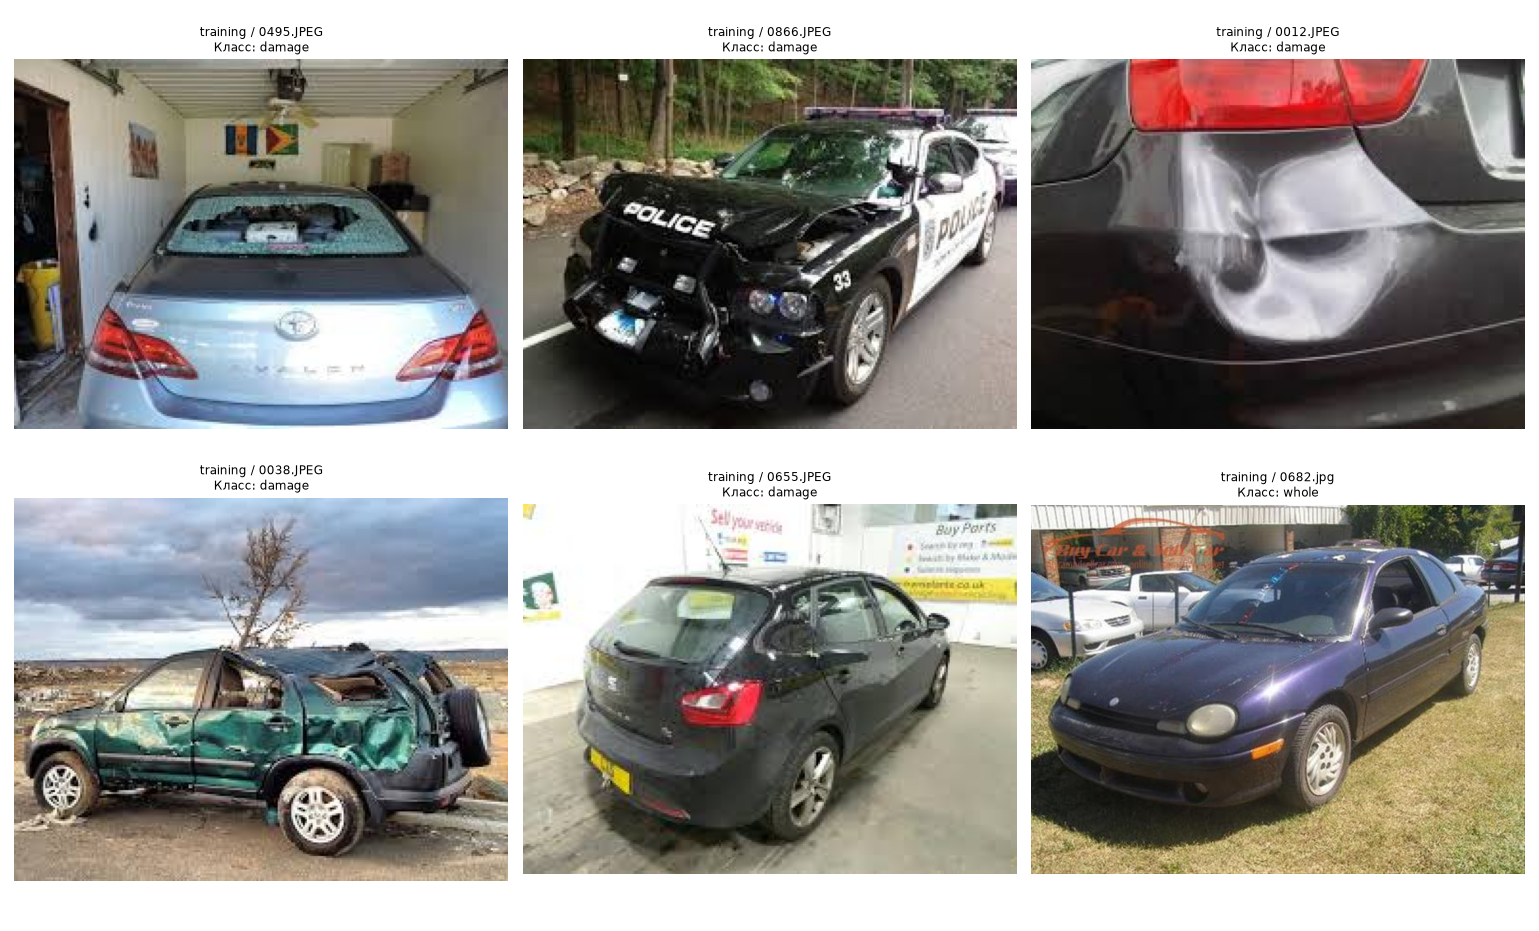

In [4]:
# Повторный запуск этой ячейки показывает новую случайную подборку.
figure, selected_samples = show_samples(
    dataset, n_images=N_IMAGES, n_cols=N_COLS, seed=SEED,
    split=SPLIT, class_filter=CLASS_FILTER,
    show_masks=SHOW_MASKS, show_boxes=SHOW_BOXES,
    show_labels=SHOW_LABELS, show_class_ids=SHOW_CLASS_IDS,
    only_annotated=ONLY_ANNOTATED,
)
